# Training Splats

Gaussian splats turn the keyframes, cameras and point cloud into a scene you can render from any
view. The `splats` stage trains Scaffold-2DGS: a sparse set of anchors, each decoding small flat
Gaussian disks with a tiny network. No later stage reads the splats; they are a final output.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from collab_splats.geometry.transforms import invert_poses
from collab_splats.preproc import frames
from collab_splats.splats import load_checkpoint, render_views
from collab_splats.utils.image import open_image, resize_image
from collab_splats.utils.io import to_uint8_hwc
from collab_splats.utils.visualization import camera_view

%run ../tutorial.py

scene = tutorial_scene("preproc", "pointcloud", "splats")

## 1. Configuration

The settings the scene trained with. The tutorial trains 3,000 steps; the production default is
30,000, so these renders are softer. Scaffold decodes color with its network, so it has no
spherical-harmonics settings.

In [2]:
print(json.dumps(scene.config["splats"], indent=2))

{
  "enabled": true,
  "primitive": "2dgs",
  "depth_conf_percentile": 20.0,
  "representation": "scaffold",
  "max_steps": 3000,
  "resolution_schedule": 300,
  "losses": {
    "opacity_reg": {
      "weight": 0
    },
    "scale_reg": {
      "weight": 0
    },
    "distortion": {
      "weight": 0.01,
      "start": 300
    },
    "normal_consistency": {
      "weight": 0.05,
      "start": 700
    }
  }
}


## 2. Training report

After training, the stage renders every training view and scores it against its frame:

- **PSNR**: how closely the render's pixels match the photo, in dB. Higher is better; above
  about 25 dB looks close.
- **SSIM**: how closely the structure (edges, texture) matches, 0 to 1. Higher is better.

The averages and the last step's losses:

In [3]:
report_path = scene.outputs["splats"].parent / "splats_quality_report.json"
report = json.loads(report_path.read_text())
summary = report["summary"]

headline = {
    "psnr (dB)": summary["psnr"],
    "ssim": summary["ssim"],
    "anchors": summary["n_gaussians"],
    "training seconds": summary["seconds"],
}
display(pd.Series(headline).round(3))
display(pd.Series(summary["final_losses"], name="final loss").round(4))

psnr (dB)               15.662
ssim                     0.511
anchors             401371.000
training seconds       182.100
dtype: float64

l1                    0.0907
ssim                  0.4717
distortion            0.0119
normal_consistency    0.1972
Name: final loss, dtype: float64

The five weakest views:

In [4]:
per_frame = pd.DataFrame(report["per_frame"])
display(per_frame.sort_values("psnr")[["image_id", "psnr", "ssim"]].head(5).round(3))

,image_id,psnr,ssim
50,1090,13.839,0.365
65,1468,14.077,0.540
38,832,14.084,0.455
86,2165,14.102,0.502
43,939,14.162,0.459


These are training views, so the scores measure fit, not quality from new viewpoints. Weak views
often have motion blur, an exposure change or content few other frames see.

## 3. Renders

Load the trained model and render four views spread over the sequence:

In [5]:
model, camera_opt, cam_to_world, intrinsics, image_ids, (height, width) = load_checkpoint(
    scene.outputs["splats"], "cuda"
)

# Four views spread over the sequence, and their source frames
shown_rows = np.linspace(0, len(image_ids) - 1, 4).astype(int)
shown_ids = [image_ids[row] for row in shown_rows]
sources = frames.read_frames(scene.images_dir, shown_ids)

# Render every view in order; keep the shown ones
renders = []

with torch.no_grad():
    for row, render in enumerate(
        render_views(model, camera_opt, cam_to_world, intrinsics, height, width)
    ):
        if row in shown_rows:
            renders.append(render["rgb"][0].cpu().numpy())

rendered = to_uint8_hwc(np.stack(renders), channels_first=False)

Photos on top, renders below, with each view's PSNR:

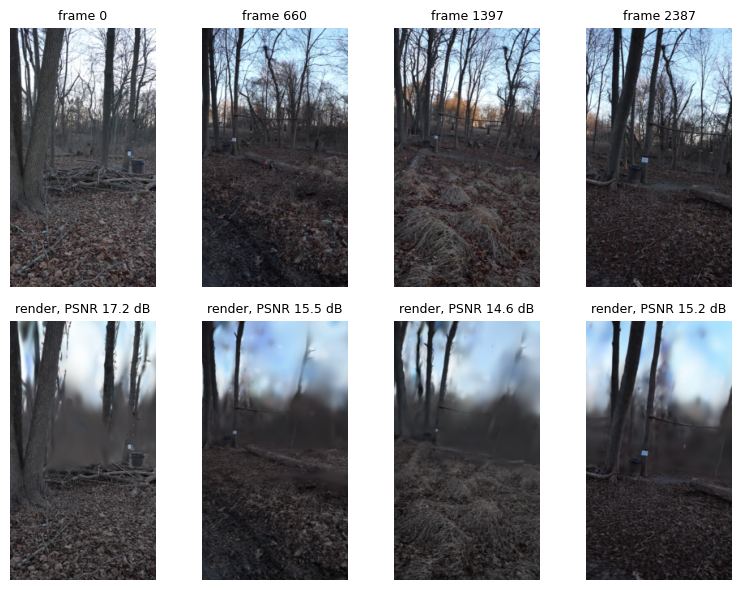

In [6]:
psnr = per_frame.set_index("image_id")["psnr"]
fig, axes = plt.subplots(2, len(shown_rows), figsize=(8, 6))

for col, frame_id in enumerate(shown_ids):
    axes[0, col].imshow(resize_image(open_image(sources[col]), 320))
    axes[1, col].imshow(resize_image(open_image(rendered[col]), 320))
    axes[0, col].set_title(f"frame {frame_id}", fontsize=9)
    axes[1, col].set_title(f"render, PSNR {psnr[frame_id]:.1f} dB", fontsize=9)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

Large flat surfaces already match; thin branches blur first at this short training length.

## 4. The whole scene

A splat renders from any camera, not just the training ones. This view sits behind the cameras,
pulled back to show the whole scene: the same view as the mesh and lifting pages. The ground the
frames saw renders sharp. Sky and far trees become a blurry shell around it, and where no frame
looked the render is black.


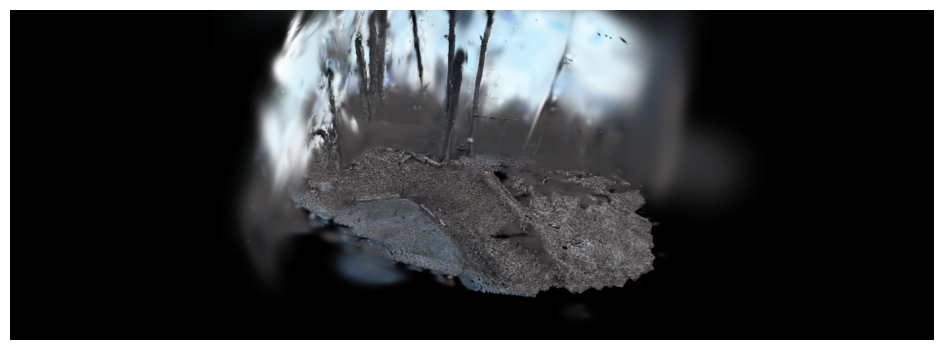

In [7]:
# View from behind the cameras, as on the mesh and lifting pages, framed on the anchors
anchors = model.params["anchors"].detach().cpu().numpy()
view = camera_view(invert_poses(cam_to_world.cpu().numpy()), anchors)
eye, focal, up = (np.asarray(view[key]) for key in ("position", "focal_point", "view_up"))

# Look-at pose in camera axes: x right, y down, z forward
forward = (focal - eye) / np.linalg.norm(focal - eye)
right = np.cross(forward, up)
right /= np.linalg.norm(right)
pose = np.eye(4)
pose[:3, :3] = np.stack([right, np.cross(forward, right), forward], axis=1)
pose[:3, 3] = eye

# Wide frame with pyvista's 30 degree vertical field of view
view_width, view_height = 1400, 500
focal_px = view_height / 2 / np.tan(np.radians(15))
camera = np.array(
    [[focal_px, 0, view_width / 2], [0, focal_px, view_height / 2], [0, 0, 1]]
)

# Render once; the color correction of the first view stands in for this one
camera_id = torch.zeros(1, dtype=torch.long, device="cuda")

with torch.no_grad():
    render, _ = model.render(
        cam_to_world.new_tensor(pose[None]),
        intrinsics.new_tensor(camera[None]),
        view_width,
        view_height,
        camera_id,
        step=None,
    )
    whole = camera_opt.color(render["rgb"], camera_id).clamp(0, 1)[0].cpu().numpy()

plt.figure(figsize=(10, 3.6))
plt.imshow(whole)
plt.axis("off")
plt.tight_layout()

## In a pipeline run

The stage writes `splats/ckpt.pt`, `splats/splats.ply` and `splats/splats_quality_report.json`.
Scaffold-2DGS at production length:

```yaml
splats:
  enabled: true
  representation: scaffold
  primitive: 2dgs
  max_steps: 30000
  losses:
    opacity_reg: {weight: 0}
    scale_reg: {weight: 0}
    distortion: {weight: 0.01, start: 3000}
    normal_consistency: {weight: 0.05, start: 7000}
```